# Smart Credit - Credit Score Classification
**Goal:** classify a customer's credit score (*Poor / Standard / Good*) from banking and credit data.

Workflow: 1) load data, 2) EDA, 3) cleaning, 4) model comparison, 5) final model + evaluation, 6) predictions on `test.csv`.
All heavy logic lives in the `creditscore/` package so the notebook, the training script and the API use identical code.

In [1]:
import sys, json; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from creditscore import config as C, cleaning as K, modeling as M
sns.set_theme(style='whitegrid')
%matplotlib inline

## 1. Load the data

In [2]:
train = pd.read_csv(C.TRAIN_PATH, low_memory=False)
test  = pd.read_csv(C.TEST_PATH,  low_memory=False)
print('train', train.shape, '| test', test.shape)
print('customers in train:', train.Customer_ID.nunique(), '| months per customer:', train.groupby('Customer_ID').size().unique())
print('test has target column?', C.TARGET in test.columns)
train.head(3).T

train (100000, 28) | test (50000, 27)
customers in train: 12500 | months per customer: [8]
test has target column? False


,0,1,2
ID,0x1602,0x1603,0x1604
Customer_ID,CUS_0xd40,CUS_0xd40,CUS_0xd40
Month,January,February,March
Name,Aaron Maashoh,Aaron Maashoh,Aaron Maashoh
Age,23,23,-500
SSN,821-00-0265,821-00-0265,821-00-0265
Occupation,Scientist,Scientist,Scientist
Annual_Income,19114.12,19114.12,19114.12
Monthly_Inhand_Salary,1824.843333,NaN,NaN
Num_Bank_Accounts,3,3,3


## 2. Exploratory data analysis

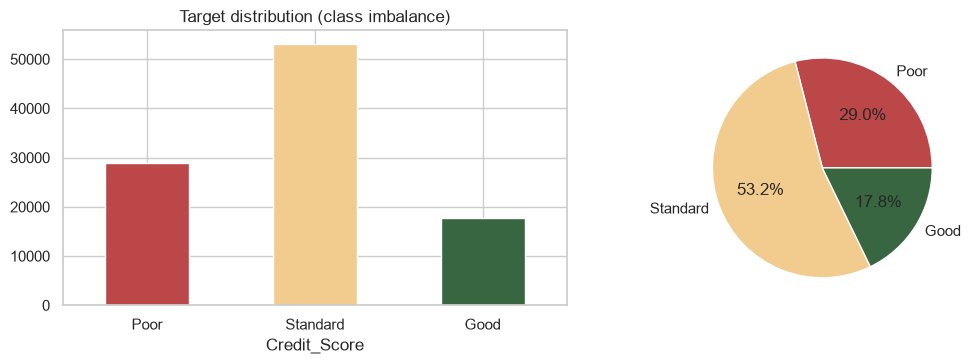

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = C.LABELS
train[C.TARGET].value_counts()[order].plot.bar(ax=ax[0], color=['#bc4749','#f2cc8f','#386641'], rot=0)
ax[0].set_title('Target distribution (class imbalance)')
(train[C.TARGET].value_counts(normalize=True)[order]*100).round(1).plot.pie(ax=ax[1], autopct='%1.1f%%', colors=['#bc4749','#f2cc8f','#386641'])
ax[1].set_ylabel(''); plt.tight_layout(); plt.show()

In [4]:
# how dirty is the raw data?  (placeholders, underscores, impossible numbers)
dirty = pd.DataFrame({
  'missing (NaN)': train.isna().sum(),
  'has "_" noise': train.astype(str).apply(lambda s: s.str.contains('_$|^_+$', regex=True).sum()),
})
dirty[(dirty > 0).any(axis=1)].sort_values('missing (NaN)', ascending=False)

,missing (NaN),"has ""_"" noise"
Monthly_Inhand_Salary,15002,0
Type_of_Loan,11408,0
Name,9985,0
Credit_History_Age,9030,0
Num_of_Delayed_Payment,7002,2744
Amount_invested_monthly,4479,4305
Num_Credit_Inquiries,1965,0
Monthly_Balance,1200,9
Annual_Income,0,6980
Age,0,4939


In [5]:
print('Age range in raw data:', pd.to_numeric(train.Age.str.replace('_',''), errors='coerce').agg(['min','max']).tolist())
print('Num_Bank_Accounts raw range:', train.Num_Bank_Accounts.agg(['min','max']).tolist())
print('Interest_Rate raw range:', train.Interest_Rate.agg(['min','max']).tolist())

Age range in raw data: [-500, 8698]
Num_Bank_Accounts raw range: [-1, 1798]
Interest_Rate raw range: [1, 5797]


## 3. Cleaning and feature engineering

Rules (see `creditscore/cleaning.py`):
- strip `_` noise and convert text to numbers; placeholders (`_`, `NM`, `!@9#%8`) become missing
- values outside plausible ranges (age -500, 5000 credit cards, ...) become missing
- missing values are filled from the **same customer's other months** (median / mode); anything left is imputed inside the model pipeline
- `Credit_History_Age` -> months; `Type_of_Loan` -> one flag per loan type; ratio features added

In [6]:
X, y, groups = M.load_xy()
print('model matrix:', X.shape, '| remaining NaN:', int(X.isna().sum().sum()))
X.describe().T[['min','50%','max']].round(2).head(18)

model matrix: (100000, 36) | remaining NaN: 0


,min,50%,max
Age,14.00,33.00,100.00
Annual_Income,7005.93,37002.58,277803.00
Num_of_Loan,0.00,3.00,9.00
Num_of_Delayed_Payment,0.00,14.00,28.00
Changed_Credit_Limit,-6.49,9.40,36.97
Outstanding_Debt,0.23,1166.16,4998.07
Amount_invested_monthly,0.00,129.36,1977.33
Monthly_Balance,0.01,337.27,1602.04
Monthly_Inhand_Salary,303.65,3095.98,15204.63
Num_Bank_Accounts,0.00,5.00,11.00


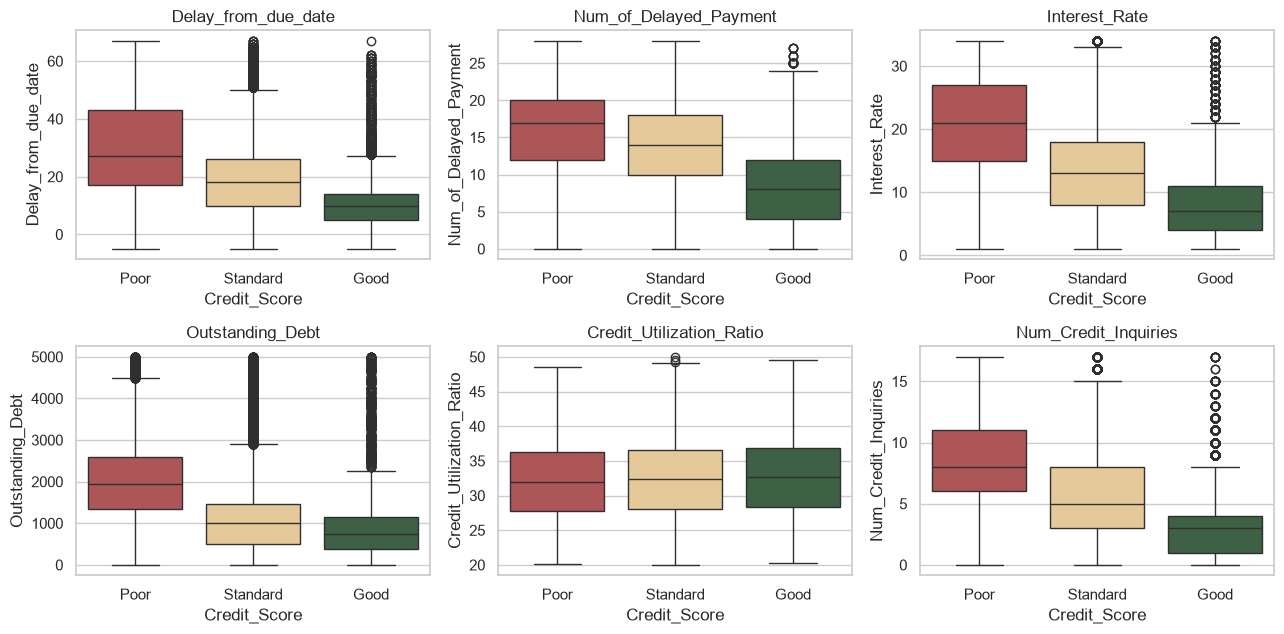

In [7]:
df = X.copy(); df['Credit_Score'] = pd.Series(y).map(C.ID_TO_LABEL).values
cols = ['Delay_from_due_date','Num_of_Delayed_Payment','Interest_Rate','Outstanding_Debt','Credit_Utilization_Ratio','Num_Credit_Inquiries']
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x='Credit_Score', y=c, order=C.LABELS, ax=ax, palette=['#bc4749','#f2cc8f','#386641'])
    ax.set_title(c)
plt.tight_layout(); plt.show()

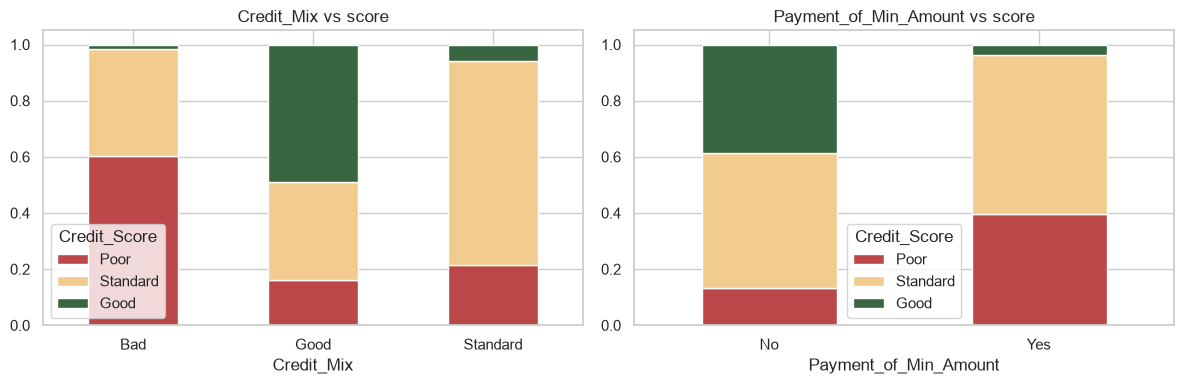

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(df.Credit_Mix, df.Credit_Score, normalize='index')[C.LABELS].plot.bar(stacked=True, ax=ax[0], rot=0, color=['#bc4749','#f2cc8f','#386641'])
ax[0].set_title('Credit_Mix vs score')
pd.crosstab(df.Payment_of_Min_Amount, df.Credit_Score, normalize='index')[C.LABELS].plot.bar(stacked=True, ax=ax[1], rot=0, color=['#bc4749','#f2cc8f','#386641'])
ax[1].set_title('Payment_of_Min_Amount vs score'); plt.tight_layout(); plt.show()

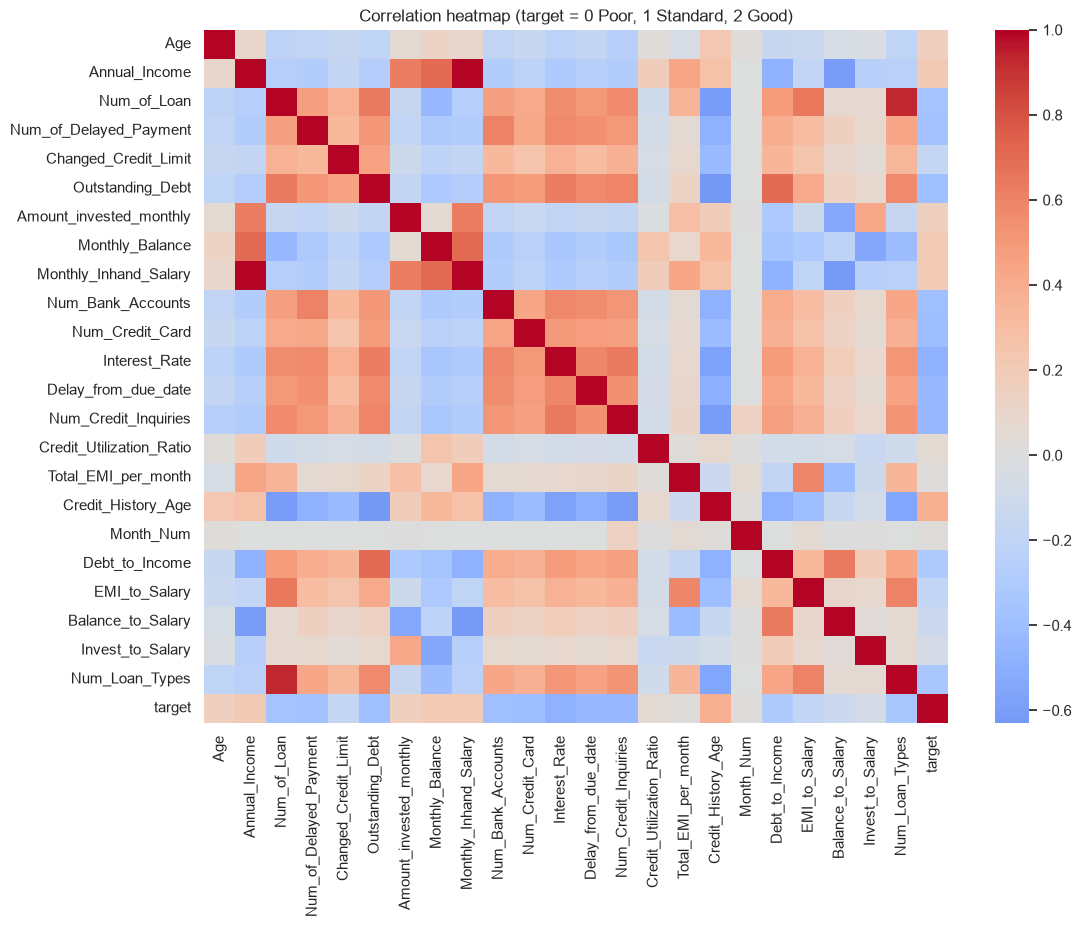

(Amount_invested_monthly    0.154
 Age                        0.160
 Monthly_Balance            0.209
 Monthly_Inhand_Salary      0.210
 Annual_Income              0.213
 Credit_History_Age         0.389
 Name: target, dtype: float64,
 Interest_Rate          -0.485
 Num_Credit_Inquiries   -0.436
 Delay_from_due_date    -0.432
 Num_Credit_Card        -0.404
 Num_Bank_Accounts      -0.388
 Outstanding_Debt       -0.387
 Name: target, dtype: float64)

In [9]:
num = X.select_dtypes('number').drop(columns=[c for c in X.columns if c.startswith('Loan_')])
corr = num.assign(target=y).corr()
plt.figure(figsize=(12, 9)); sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation heatmap (target = 0 Poor, 1 Standard, 2 Good)'); plt.show()
corr['target'].drop('target').sort_values().round(3).tail(6), corr['target'].drop('target').sort_values().round(3).head(6)

## 4. Model comparison
Customer-grouped 80/20 split: all 8 months of a customer stay on the same side, so the score is not inflated by memorising customers. Class imbalance is handled with balanced class weights. Results come from the full run of `python -m creditscore.train` (RandomForest takes ~1 min on a laptop).

,accuracy,macro_f1,weighted_f1,seconds
model,,,,
Random Forest,0.7104,0.6961,0.7124,48.4
LightGBM,0.7000,0.6938,0.7025,17.2
HistGradientBoosting,0.6968,0.6908,0.6993,12.5
Logistic Regression,0.6710,0.6658,0.6740,1.9


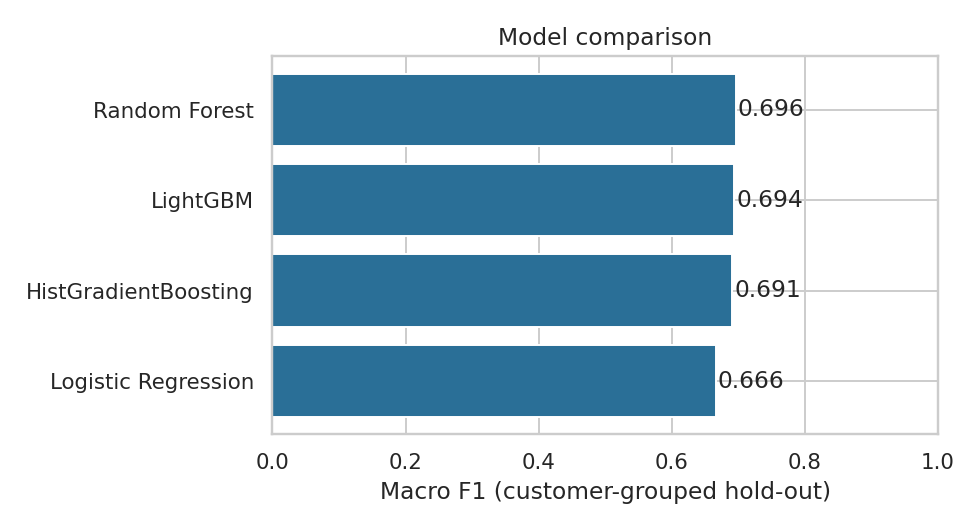

In [10]:
res = json.load(open('../reports/metrics.json'))
comp = pd.DataFrame(res['model_comparison']).set_index('model')
display(comp[['accuracy','macro_f1','weighted_f1','seconds']])
display(Image('../reports/figures/model_comparison.png'))

In [11]:
pd.DataFrame(res['tuning'])[['num_leaves','learning_rate','n_estimators','min_child_samples','reg_lambda','accuracy','macro_f1']]

,num_leaves,learning_rate,n_estimators,min_child_samples,reg_lambda,accuracy,macro_f1
0,63,0.05,400,30,NaN,0.7000,0.6938
1,127,0.03,600,30,NaN,0.7014,0.6933
2,63,0.08,300,100,5.0,0.6974,0.6906
3,31,0.05,400,50,NaN,0.6944,0.6904


## 5. Final model - hold-out evaluation (live re-fit on 80% of customers)

              precision    recall  f1-score   support

        Poor      0.671     0.747     0.707      5726
    Standard      0.816     0.637     0.715     10580
        Good      0.556     0.808     0.659      3694

    accuracy                          0.700     20000
   macro avg      0.681     0.731     0.694     20000
weighted avg      0.726     0.700     0.703     20000



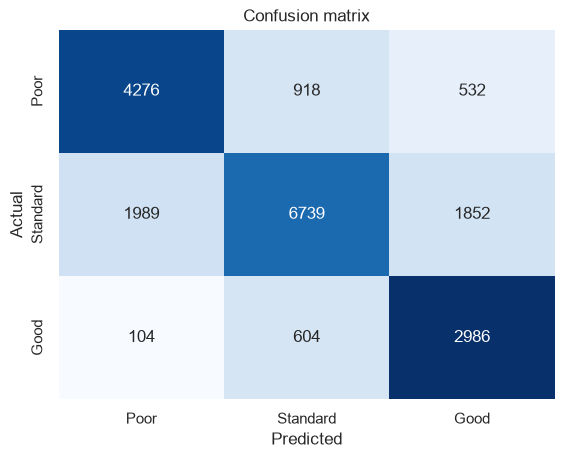

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
tr, va = M.grouped_split(X, y, groups)
model = M.lightgbm_pipeline(**res['best_params']).fit(X.iloc[tr], y[tr])
pred = model.predict(X.iloc[va])
print(classification_report(y[va], pred, target_names=C.LABELS, digits=3))
cm = confusion_matrix(y[va], pred)
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt='d', cmap='Blues', xticklabels=C.LABELS, yticklabels=C.LABELS, cbar=False)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix'); plt.show()

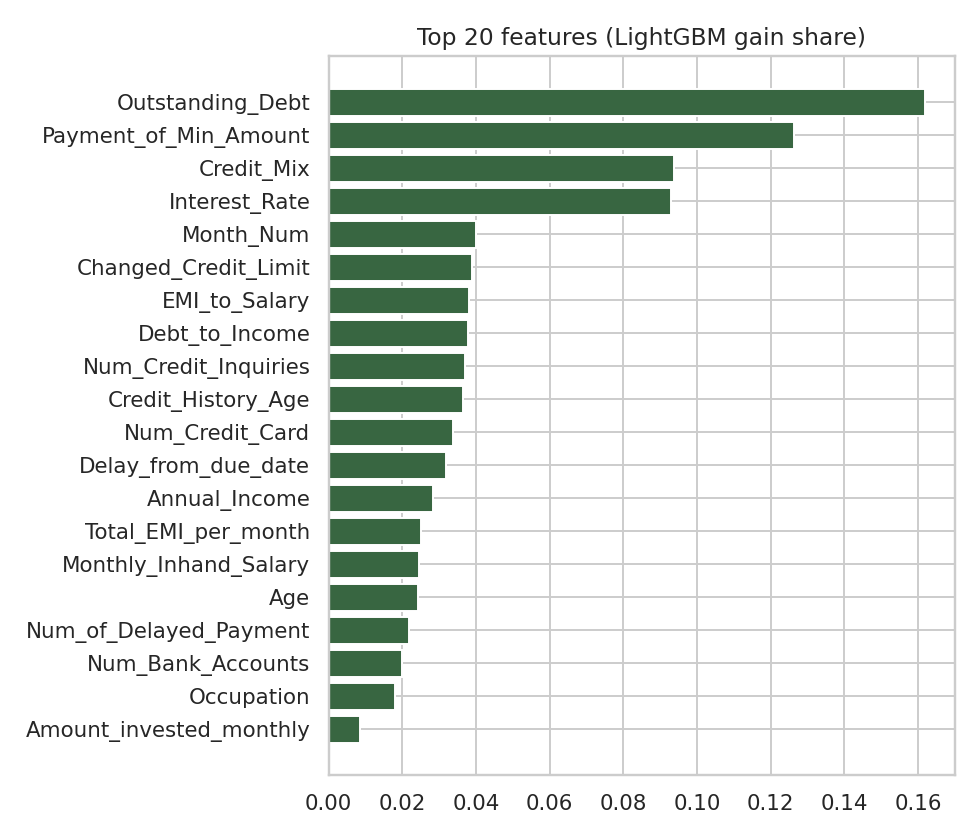

In [13]:
display(Image('../reports/figures/feature_importance.png'))

## 6. Predictions on `test.csv`
`test.csv` has no `Credit_Score` column, so it cannot be scored here; predictions are written to `reports/test_predictions.csv` by the training script.

In [14]:
from creditscore.predict import predict_frame
sub = pd.read_csv('../reports/test_predictions.csv')
print(sub.shape); display(sub.head())
print(sub.Credit_Score.value_counts(normalize=True).round(3).to_dict())

(50000, 8)


,ID,Customer_ID,Month,Credit_Score,class_id,prob_Poor,prob_Standard,prob_Good
0,0x160a,CUS_0xd40,September,Good,2,0.0614,0.1250,0.8135
1,0x160b,CUS_0xd40,October,Good,2,0.0448,0.1509,0.8043
2,0x160c,CUS_0xd40,November,Good,2,0.0628,0.1217,0.8156
3,0x160d,CUS_0xd40,December,Good,2,0.0354,0.1153,0.8493
4,0x1616,CUS_0x21b1,September,Good,2,0.0334,0.1568,0.8097


{'Standard': 0.394, 'Poor': 0.335, 'Good': 0.271}


## 7. Conclusions
- Best model: tuned **LightGBM** (about 70% accuracy / 0.69 macro-F1 on unseen customers).
- Most influential signals (LightGBM gain): outstanding debt, whether only the minimum amount is paid, credit mix and interest rate.
- Errors are mostly between neighbouring classes: *Standard* has the lowest recall (0.64, often mistaken for Poor or Good) and *Good* the lowest precision (0.56). Almost no Good customers are labelled Poor.
- Adding per-customer averages over all months only gave about +0.5 pt accuracy in a quick test, so the simpler single-record model was kept (it also works for the single-record API).
- The model is served through a FastAPI REST API (`api/main.py`) for single and batch predictions.